# Fitting the Gaia astrometry of a single-planet system

This notebook
1. simulates Gaia DR5 epoch astrometry of a star with one giant planet,
2. fits the orbit (a search over the nonlinear parameters $P$, $\phi_p$, $e$, with the linear parameters solved exactly),
3. plots the orbit on the sky and the along-scan residuals, and
4. samples the posterior with MCMC ([emcee](https://emcee.readthedocs.io)) and shows a corner plot.

It needs `gaiamockplus`, `emcee` and `corner`. The first simulation downloads the Gaia scanning-law data (286 MB, once).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
import gaiamockplus as gmp
from gaiamockplus import gaiamock

%config InlineBackend.figure_format = 'retina'

c_funcs = gaiamock.read_in_C_functions()  # compiled functions used by gaiamock's routines
rng = np.random.default_rng(23)           # random numbers for the simulation (reproducible)
M_JUP = 1/1047.57                         # Jupiter mass in Msun

## 1. Simulate the epoch astrometry

A planet is a dict of its orbital elements and mass. As in gaiamock, periods and times are in days ($T_p$ is the time of periastron relative to the reference epoch of the data release), angles are in radians, and masses are in $M_\odot$. $\omega$ is the argument of periastron of the *star's* orbit.

In [2]:
# the star: a 0.8 Msun main-sequence star at 100 pc
m_star = 0.8               # Msun
parallax = 10.0            # mas
phot_g_mean_mag = 11.1     # G magnitude of such a star at 100 pc
ra, dec = 25.0, -13.0      # deg
pmra, pmdec = 12.0, 30.0   # mas/yr

# the planet: 8 Jupiter masses at 4 AU (period from Kepler's third law, neglecting the planet's mass)
planet = dict(period=365.25*4.0**1.5/np.sqrt(m_star), Tp=500.0, ecc=0.2,
              Omega=np.radians(110.0), inc=np.radians(60.0), w=np.radians(50.0), m_planet=8*M_JUP)

data = gmp.predict_astrometry_planets(ra=ra, dec=dec, parallax=parallax, pmra=pmra, pmdec=pmdec, m_star=m_star,
                                      planets=[planet], phot_g_mean_mag=phot_g_mean_mag, data_release='dr5',
                                      c_funcs=c_funcs, rng=rng)
t_ast_yr, psi, plx_factor, ast_obs, ast_err = data  # times (yr), scan angles, parallax factors, along-scan positions and errors (mas)

a0_true = gmp.get_planet_a0_mas(m_star, [planet], parallax)[0]
print(f'{len(t_ast_yr)} field-of-view transits; P = {planet["period"]/365.25:.2f} yr; star\'s reflex semimajor axis '
      f'a0 = {a0_true:.3f} mas; median uncertainty {np.median(ast_err):.3f} mas')

166 field-of-view transits; P = 8.94 yr; star's reflex semimajor axis a0 = 0.379 mas; median uncertainty 0.047 mas


## 2. Fit the orbit

`fit_astrometry_planets` searches for the nonlinear parameters $(P, \phi_p, e)$ with gaiamock's default optimizer (a circular-orbit periodogram, a scan in $e$ and $\phi_p$ at the best periods, and Nelder-Mead polishing). For each trial, the 9 linear parameters are solved exactly by weighted least squares: the position offsets, parallax and proper motion, and the Thiele-Innes elements $A, B, F, G$. The result contains the best-fit parameter vector `theta`, the Campbell elements, the planet mass (given `m_star`), and uncertainties (inflated by `uncertainty_scale`, as in gaiamock).

In [3]:
res = gmp.fit_astrometry_planets(*data, n_planets=1, m_star=m_star)
fit = res['planets'][0]

print(f"chi2 = {res['chi2_history'][0]:.0f} (no planet) -> {res['chi2']:.0f} (one planet) for {res['n_obs']} measurements")
print('best fit:', ', '.join(f'{name} = {value:.4g}' for name, value in zip(res['theta_names'], res['theta'])))

chi2 = 1899 (no planet) -> 170 (one planet) for 166 measurements
best fit: ra_off = -0.005381, dec_off = -0.00344, parallax = 10, pmra = 12, pmdec = 30, period_0 = 3299, ecc_0 = 0.1922, phi_p_0 = 0.8692, A_0 = -0.2237, B_0 = 0.2112, F_0 = -0.03775, G_0 = -0.2967


In [4]:
# compare with the truth
rows = [('parallax [mas]', parallax, res['parallax'], res['sig_parallax']),
        ('P [yr]', planet['period']/365.25, fit['period']/365.25, fit['sig_period']/365.25),
        ('e', planet['ecc'], fit['ecc'], fit['sig_ecc']),
        ('a0 [mas]', a0_true, fit['a0_mas'], fit['sig_a0_mas']),
        ('m_p [M_Jup]', planet['m_planet']/M_JUP, fit['m_planet']/M_JUP, fit['sig_m_planet']/M_JUP),
        ('inc [deg]', 60.0, np.degrees(fit['inc']), np.degrees(fit['sig_inc'])),
        ('w [deg]', 50.0, np.degrees(fit['w']), np.degrees(fit['sig_w'])),
        ('Omega [deg]', 110.0, np.degrees(fit['Omega']), np.degrees(fit['sig_Omega']))]
print(f"{'':15s} {'true':>8s} {'fit':>16s}")
for label, true, value, sigma in rows:
    print(f'{label:15s} {true:8.3f} {value:8.3f} +/- {sigma:.3f}')

                    true              fit
parallax [mas]    10.000   10.002 +/- 0.009
P [yr]             8.944    9.033 +/- 0.148
e                  0.200    0.192 +/- 0.048
a0 [mas]           0.379    0.383 +/- 0.013
m_p [M_Jup]        8.000    8.012 +/- 0.282
inc [deg]         60.000   59.468 +/- 2.026
w [deg]           50.000   43.629 +/- 15.010
Omega [deg]      110.000  110.805 +/- 2.379


Astrometry alone cannot distinguish $(\Omega, \omega)$ from $(\Omega + \pi, \omega + \pi)$, so $\Omega$ is returned in $[0, \pi)$ (radial velocities break this degeneracy).

## 3. The orbit on the sky and the along-scan residuals

Gaia measures only the along-scan coordinate. In the sky plot (gaiamock's `plot_2d_orbit_and_residuals`), each measurement is placed at the best-fit orbit position at that time, offset by its residual along the scan direction (with its error bar along the same direction); the grey square marks periastron. The second figure shows the residuals of the best-fit models without and with the planet.

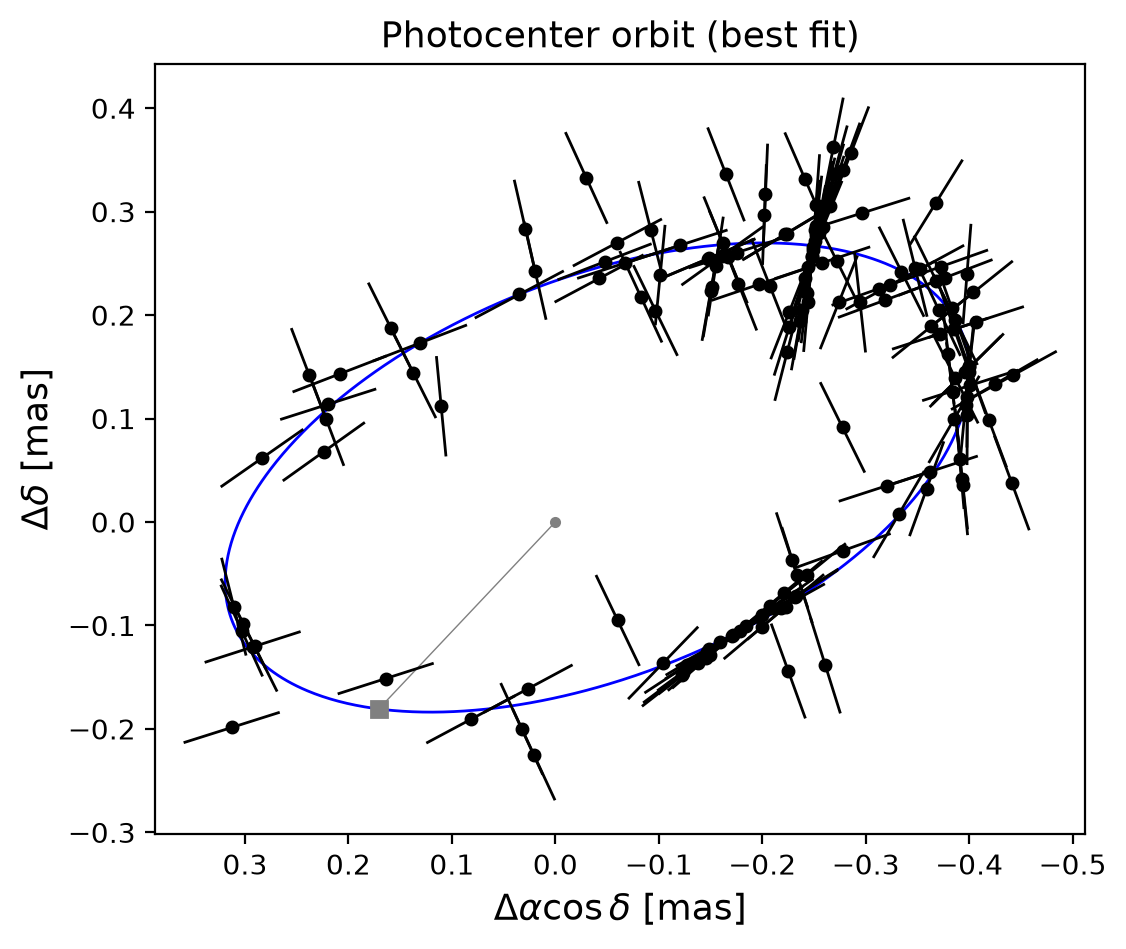

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
gaiamock.plot_2d_orbit_and_residuals(*data, period=fit['period'], ecc=fit['ecc'], Tp=fit['Tp'],
                                     delta_ra=res['ra_off'], delta_dec=res['dec_off'], parallax=res['parallax'],
                                     pmra=res['pmra'], pmdec=res['pmdec'], A=fit['A'], B=fit['B'], F=fit['F'], G=fit['G'],
                                     data_release='dr5', c_funcs=c_funcs, ax=ax)
ax.set_aspect('equal', adjustable='datalim')
ax.set_xlabel(r'$\Delta\alpha\cos\delta$ [mas]', fontsize=13)
ax.set_ylabel(r'$\Delta\delta$ [mas]', fontsize=13)
ax.set_title('Photocenter orbit (best fit)', fontsize=13)
plt.show()

single star chi2: 1898.86
binary star chi2: 169.84


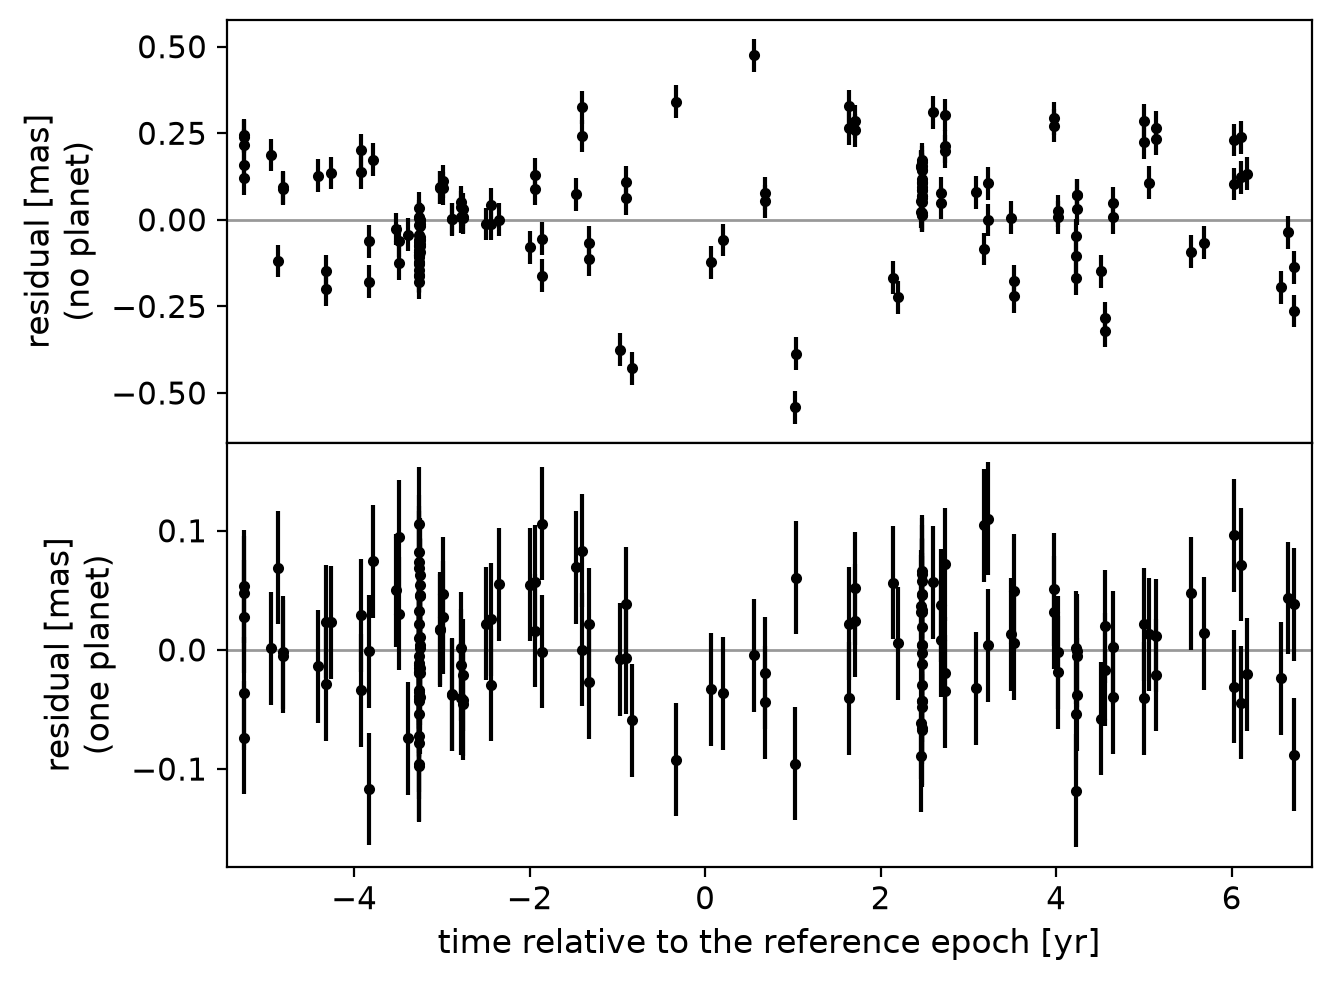

In [6]:
gaiamock.plot_residuals(*data, theta_array=[fit['period'], fit['phi_p'], fit['ecc']], c_funcs=c_funcs)
fig = plt.gcf()
fig.set_size_inches(7, 5.5)
for ax, label in zip(fig.axes, ['no planet', 'one planet']):
    ax.axhline(0, color='0.6', lw=1, zorder=0)
    ax.tick_params(labelsize=11)
    ax.set_ylabel(f'residual [mas]\n({label})', fontsize=12)
fig.axes[-1].set_xlabel('time relative to the reference epoch [yr]', fontsize=12)
plt.show()

## 4. MCMC

`log_likelihood_astrometry_planets` evaluates the likelihood of the orbit's nonlinear parameters. By default, the 9 parameters on which the model depends linearly (the position offsets, proper motion and parallax, and the Thiele-Innes elements $A$, $B$, $F$, $G$) are integrated out of the likelihood analytically, with flat priors, so the walkers sample only $P$, $e$, $\phi_p$ (and the jitter below): 4 parameters instead of 13. This gives exactly the posterior of sampling all 13 with flat priors on the linear ones, but the chain converges much faster. After the MCMC, `expand_marginal_samples` draws the linear parameters of each sample from their conditional posterior, which is Gaussian. The priors on the sampled parameters are uniform, with bounds only where needed ($0 \le e < 1$, $P$ within the search range); $\phi_p$ is kept within $\pi$ of its best-fit value: the likelihood is periodic in $\phi_p$, so this window contains every orbit exactly once, whereas without it the walkers could drift apart by multiples of $2\pi$, which would stall the chain.

The reported uncertainties of Gaia epoch astrometry do not include all of the noise (gaiamock's simulations of stars brighter than G = 13 add unmodeled noise with $\sigma$ drawn from U(0, 0.04) mas). So the likelihood includes an astrometric jitter $s$, added in quadrature to each epoch's uncertainty (`fit_ast_jitter=True`; $s$ is the last parameter, with a uniform prior on [0, 0.5) mas). `estimate_astrometric_jitter` gives its starting value: the jitter that makes the reduced $\chi^2$ of the best fit 1.

`initial_walkers` starts the walkers in a small ball around the best fit, scaled by the fit's uncertainties (and inside the prior), in the sampled parameters (`sampled_names(res)`), with the jitter appended.

In [7]:
phi0 = dict(zip(res['theta_names'], res['theta']))['phi_p_0']  # best-fit value

def log_prior(theta):
    P, e, phi_p, s = theta
    if 10 < P < 1e4 and 0 <= e < 1 and abs(phi_p - phi0) < np.pi and 0 <= s < 0.5:
        return 0.0
    return -np.inf

def log_prob(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + gmp.log_likelihood_astrometry_planets(theta, t_ast_yr, psi, plx_factor, ast_obs, ast_err, fit_ast_jitter=True)

s0 = gmp.estimate_astrometric_jitter(res, ast_err)
print(f'starting astrometric jitter: {1e3*s0:.1f} microarcsec')
nwalkers, nsteps = 50, 5500
p0 = gmp.initial_walkers(res, nwalkers, log_prob=log_prior, ast_jitter=s0, rng=rng)
np.random.seed(23)  # emcee draws its moves from numpy's global random state
sampler = emcee.EnsembleSampler(nwalkers, p0.shape[1], log_prob)
sampler.run_mcmc(p0, nsteps, progress=True);

starting astrometric jitter: 15.2 microarcsec


In [8]:
# convergence: the chain should be much longer than the autocorrelation time (emcee suggests > 50 times; tol=0: estimate it whatever the chain length)
tau = sampler.get_autocorr_time(tol=0)
print('autocorrelation times [steps]:', ', '.join(f'{n} {t:.0f}' for n, t in zip(gmp.sampled_names(res) + ['ast_jitter'], tau)))
print(f'chain length / longest autocorrelation time = {nsteps/tau.max():.0f}')

# discard the burn-in (5 autocorrelation times) and thin the chain
burn, thin = int(5*tau.max()), int(tau.max()/2)
samples = sampler.get_chain(discard=burn, thin=thin, flat=True)
print(f'{len(samples)} samples after discarding {burn} steps of burn-in and thinning by {thin}')

# draw the linear parameters of each sample: samples of all parameters, ordered like res['theta'], then the jitter
samples = gmp.expand_marginal_samples(samples, res, ast_data=data, fit_ast_jitter=True, rng=rng)

autocorrelation times [steps]: period_0 48, ecc_0 50, phi_p_0 45, ast_jitter 49
chain length / longest autocorrelation time = 109
10450 samples after discarding 251 steps of burn-in and thinning by 25


## 5. Corner plot

The physical parameters are computed for each sample (the parallax is shown relative to its best-fit value): the Campbell elements $(a_0, \Omega, \omega, i)$ from the Thiele-Innes elements, and the planet mass from $a_0$, $P$, $\varpi$ and the stellar mass. The red lines mark the true values (the simulator does not return the value of its unmodeled noise, so the jitter has none).

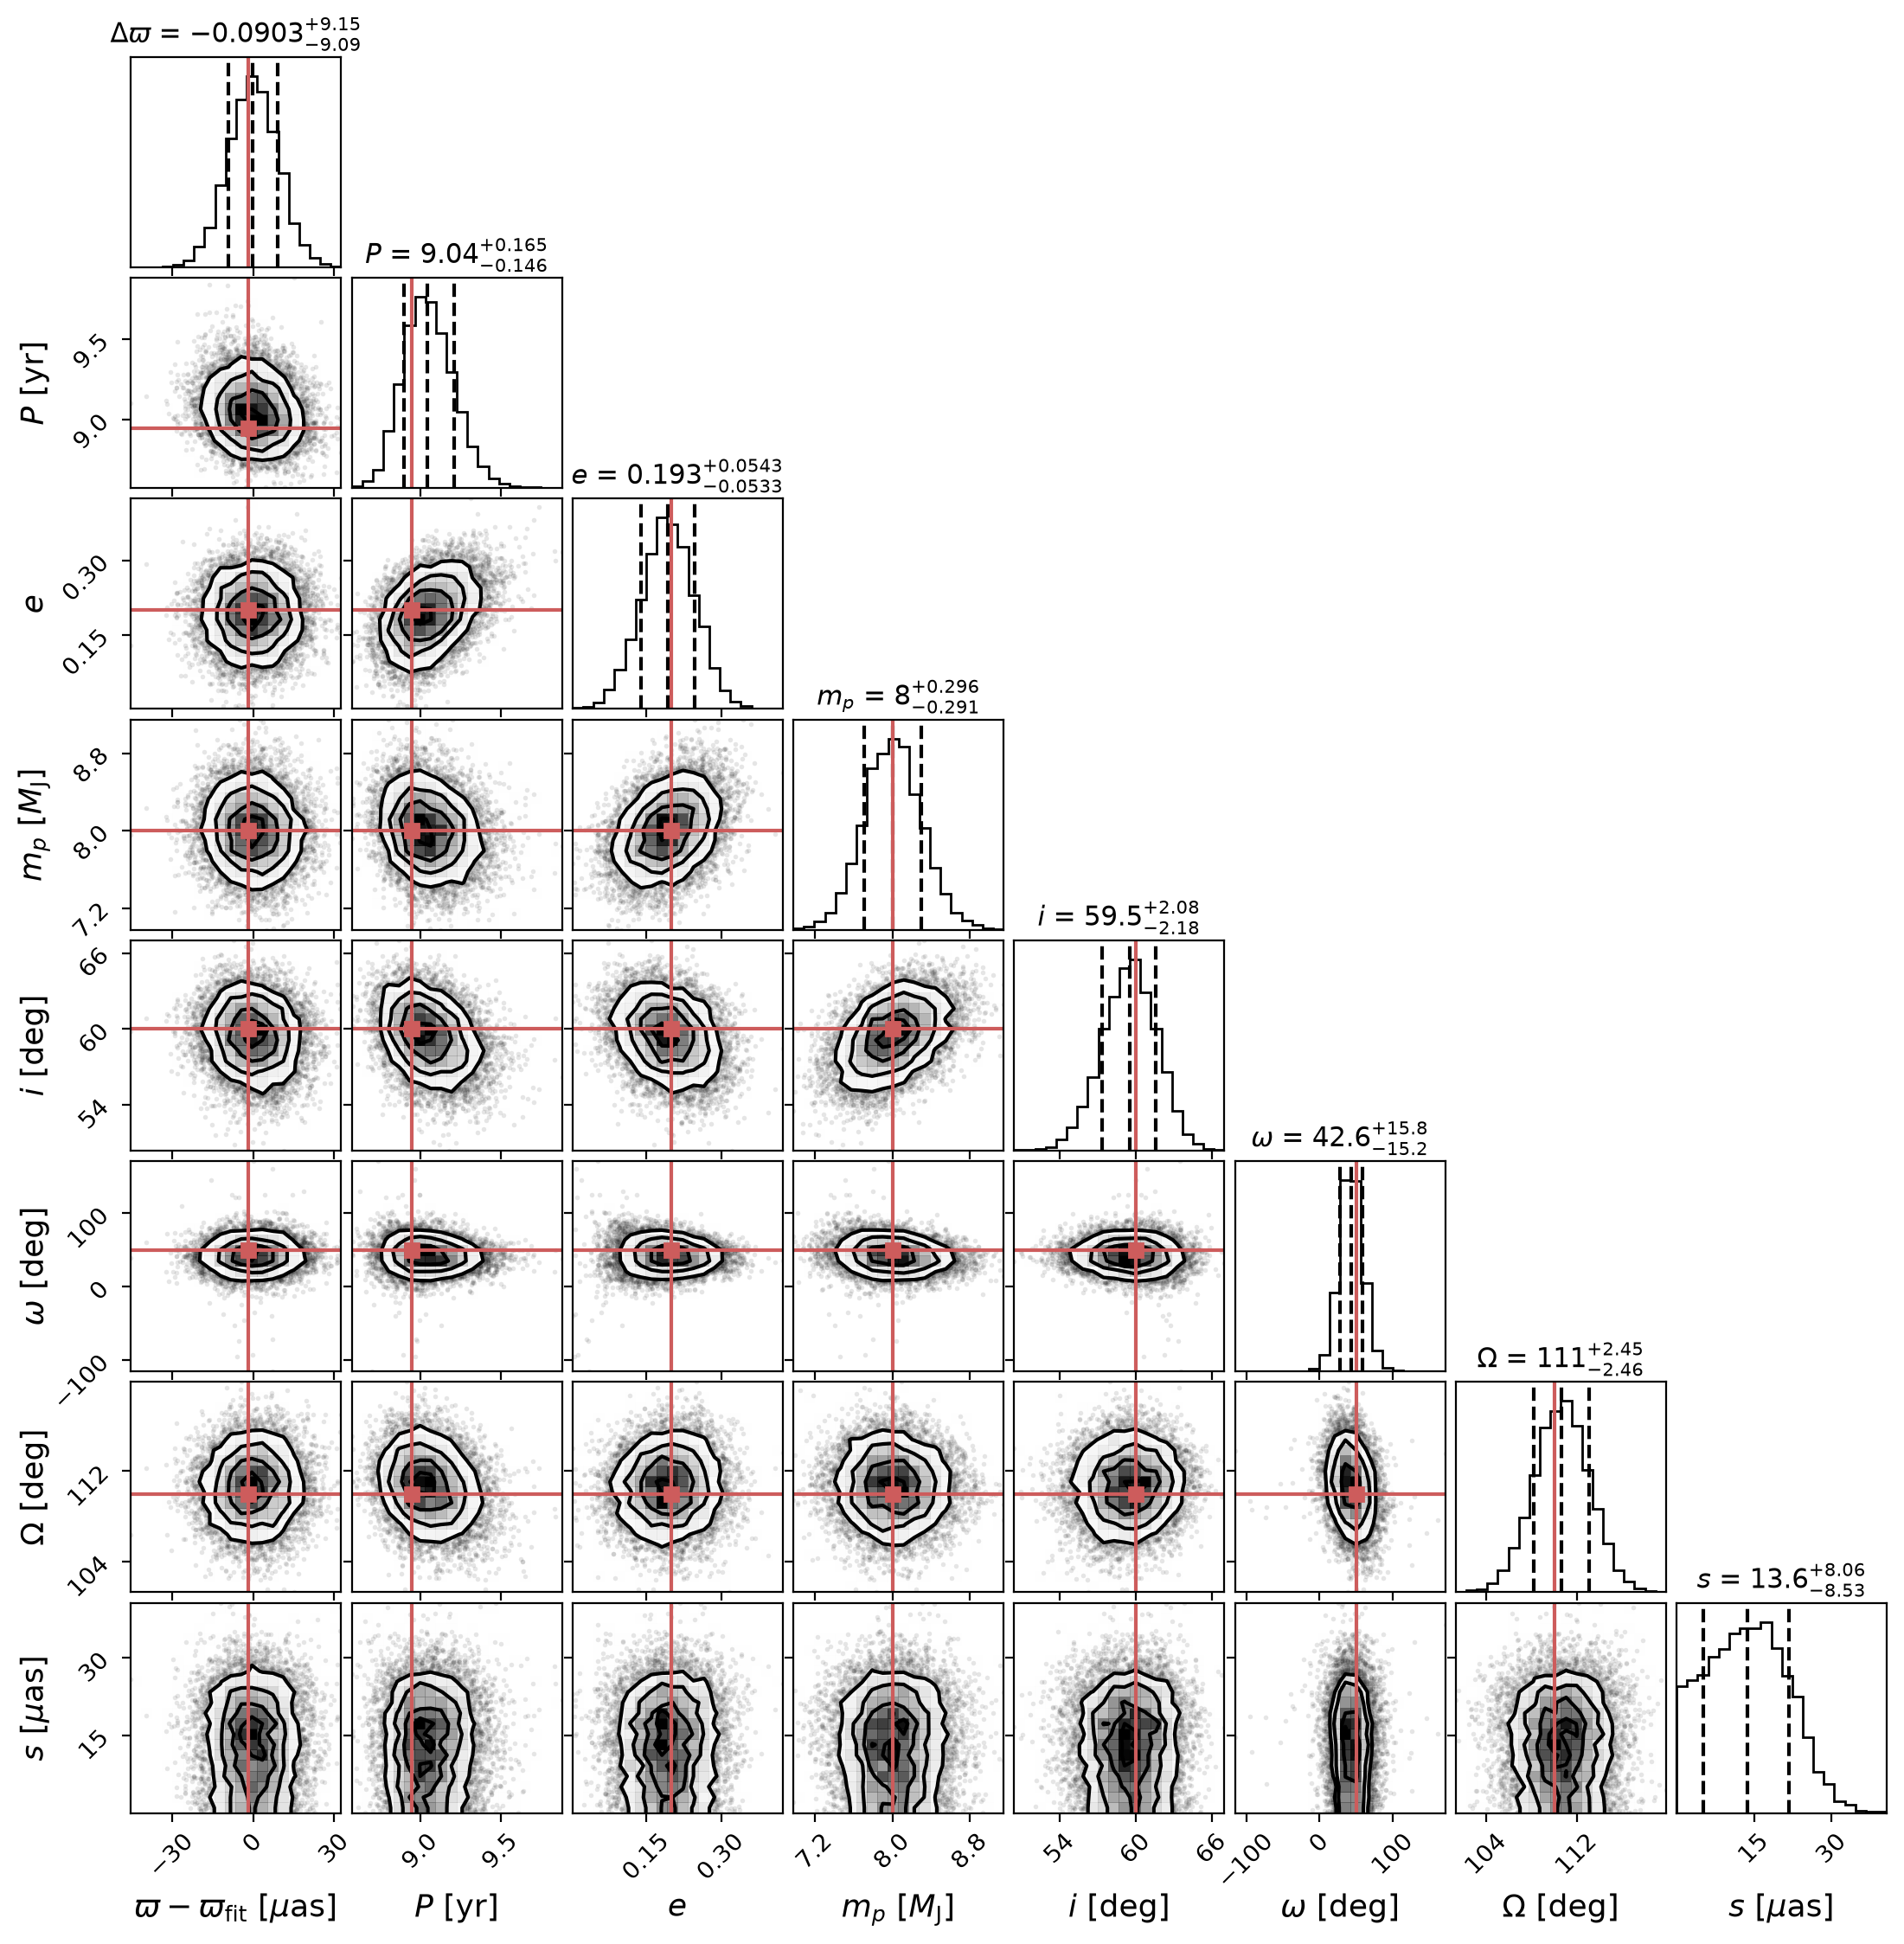

In [9]:
plx_s, P_s, e_s = samples[:, 2], samples[:, 5], samples[:, 6]
a0_s, Omega_s, w_s, inc_s = gaiamock.get_Campbell_elements(*samples[:, 8:12].T)  # from A, B, F, G
m_s = gmp.get_dark_companion_mass(a0_mas=a0_s, period=P_s, parallax=plx_s, m1=m_star)
w_s = fit['w'] + np.angle(np.exp(1j*(w_s - fit['w'])))  # w is an angle: keep it continuous around the best fit

corner_samples = np.column_stack([1e3*(plx_s - res['parallax']), P_s/365.25, e_s, m_s/M_JUP, np.degrees(inc_s), np.degrees(w_s), np.degrees(Omega_s),
                                  1e3*samples[:, -1]])
labels = [r'$\varpi - \varpi_\mathrm{fit}$ [$\mu$as]', r'$P$ [yr]', r'$e$', r'$m_p$ [$M_\mathrm{J}$]', r'$i$ [deg]', r'$\omega$ [deg]', r'$\Omega$ [deg]',
          r'$s$ [$\mu$as]']
truths = [1e3*(parallax - res['parallax']), planet['period']/365.25, planet['ecc'], planet['m_planet']/M_JUP, 60.0, 50.0, 110.0, None]

titles = [r'$\Delta\varpi$', r'$P$', r'$e$', r'$m_p$', r'$i$', r'$\omega$', r'$\Omega$', r'$s$']
fig = corner.corner(corner_samples, labels=labels, titles=titles, truths=truths, truth_color='indianred',
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3g', max_n_ticks=3, labelpad=0.08,
                    label_kwargs=dict(fontsize=13), title_kwargs=dict(fontsize=11))
fig.set_size_inches(11, 11)
plt.show()

In [10]:
# the posterior widths agree with the fit's uncertainties (inflated as in gaiamock, rather than with a jitter)
for label, s, sigma_fit in [('P [yr]', P_s/365.25, fit['sig_period']/365.25), ('e', e_s, fit['sig_ecc']),
                            ('m_p [M_Jup]', m_s/M_JUP, fit['sig_m_planet']/M_JUP), ('inc [deg]', np.degrees(inc_s), np.degrees(fit['sig_inc']))]:
    lo, med, hi = np.percentile(s, [16, 50, 84])
    print(f'{label:12s} MCMC {med:.3f} (+{hi - med:.3f} / -{med - lo:.3f});  fit uncertainty {sigma_fit:.3f}')

P [yr]       MCMC 9.044 (+0.165 / -0.146);  fit uncertainty 0.148
e            MCMC 0.193 (+0.054 / -0.053);  fit uncertainty 0.048
m_p [M_Jup]  MCMC 8.004 (+0.296 / -0.291);  fit uncertainty 0.282
inc [deg]    MCMC 59.526 (+2.080 / -2.177);  fit uncertainty 2.026
